# Proyecto EVA: exploración y ruta de desarrollo

**Curso:** Despliegue de soluciones analíticas — MIAD 2026  
**Equipo:** María Valentina Páez Romero, Samuel Esteban Vargas, Felipe Delgadillo Barrera y Juan Esteban Misas Ramírez  
**Entrega:** exploración de la base agrícola EVA 2019–2025

Este cuaderno documenta el entendimiento del problema, la preparación de los datos, la exploración orientada a la hipótesis de negocio, las limitaciones actuales y los próximos pasos para construir el modelo, la API, el tablero y el despliegue.

## 1. Problema y contexto

El rendimiento de los cultivos depende mucho de la lluvia y la temperatura, y Colombia enfrenta hoy un episodio de El Niño. El Ideam y el Ministerio de Ambiente confirmaron oficialmente su inicio, con impactos que podrían ser más intensos entre noviembre de 2026 y enero de 2027. Ya hay señales: en junio de 2026 se registró déficit de lluvias en 28 de los 32 departamentos, con una caída de 29,4% frente a junio de 2025. La exposición del agro es alta porque, según Corficolombiana, el 72% de la agricultura del país depende de las aguas lluvias, y entre los cultivos más expuestos a un evento intenso se cuentan el arroz y la caña de azúcar. 
colombia confirma fenomeno el nino impacto agro 2026
 +4

Pese a esto, quienes planean (secretarías de agricultura, gremios, aseguradoras agrícolas) carecen de una herramienta abierta y municipal que estime cuánto podría cambiar el rendimiento de un cultivo según el escenario climático. Este proyecto propone construir un prototipo que, con la información de las Evaluaciones Agropecuarias Municipales (EVA) de la UPRA, estime el rendimiento de arroz, papa y caña por municipio y periodo, y permita explorar escenarios de El Niño, neutro y La Niña.

### Pregunta de negocio
¿Cuál es el rendimiento esperado (t/ha) de arroz, papa y caña de azúcar en un municipio colombiano en un periodo dado, y cómo cambia ese rendimiento bajo un escenario de El Niño frente a uno neutro?

### Preguntas de apoyo:

¿Cómo ha evolucionado históricamente el rendimiento de cada cultivo y variante (2019-2025)?
¿Se ve una caída del rendimiento en los periodos de El Niño de 2023-2024?
¿Qué tan distinta es la respuesta entre arroz de riego y de secano?

## 2. Fuente y flujo de datos

La fuente principal es **Evaluaciones Agropecuarias Municipales (EVA) 2019–2025, Base Agrícola**, publicada por la UPRA en datos.gov.co mediante la API Socrata (`uejq-wxrr`).

El flujo reproducible del repositorio es:

```text
API de datos.gov.co -> JSON crudo versionado con DVC
                    -> limpieza y transformación
                    -> CSV de modelado
                    -> tablas y gráficas de EDA
```

La descarga se realiza con `src/descargar_eva.py`, la transformación con `src/limpiar_eva.py` y la EDA automatizada con `src/eda_eva.py`. El JSON crudo no se versiona en Git; su archivo `.dvc` permite recuperar el dato desde el almacenamiento configurado por el equipo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

RAIZ = Path.cwd()
if not (RAIZ / "data").exists() and (RAIZ.parent / "data").exists():
    RAIZ = RAIZ.parent

RUTA_CRUDO = RAIZ / "data" / "raw" / "eva_2019_2025.json"
RUTA_MODELO = RAIZ / "data" / "processed" / "eva_modelo.csv"
RUTA_EDA = RAIZ / "data" / "processed" / "eda"

print(f"Directorio del proyecto: {RAIZ}")
print(f"Existe el dato crudo: {RUTA_CRUDO.exists()}")
print(f"Existe el dato procesado: {RUTA_MODELO.exists()}")

Matplotlib is building the font cache; this may take a moment.


Directorio del proyecto: /Users/felipedelgadillo/Documents/universidades/Uniandes/maestria/2026-15_despliegue_de_soluciones/proyecto_DSA
Existe el dato crudo: True
Existe el dato procesado: True


## 3. Carga y revisión inicial

Se cargan dos capas con propósitos distintos:

- **Capa cruda:** evidencia de la fuente y control de cobertura original.
- **Capa procesada:** tabla analítica con cultivos, periodos y variantes definidos por el equipo.

La capa procesada es la que se utilizará para las tablas y gráficas de esta exploración.

In [2]:
if not RUTA_MODELO.exists():
    raise FileNotFoundError(
        "No existe data/processed/eva_modelo.csv. "
        "Ejecute primero: python src/limpiar_eva.py"
    )

datos = pd.read_csv(RUTA_MODELO)
datos["a_o"] = pd.to_numeric(datos["a_o"], errors="coerce").astype("Int64")
for columna in ["rea_sembrada", "rea_cosechada", "producci_n", "rendimiento"]:
    datos[columna] = pd.to_numeric(datos[columna], errors="coerce")

print(f"Filas procesadas: {len(datos):,}")
print(f"Columnas procesadas: {datos.shape[1]}")
display(datos.head())

Filas procesadas: 12,490
Columnas procesadas: 13


,c_digo_dane_departamento,departamento,c_digo_dane_municipio,municipio,cultivo,periodo,a_o,ciclo_del_cultivo,variante,rea_sembrada,rea_cosechada,producci_n,rendimiento
0,50,Meta,50006,Acacías,Arroz,2019A,2019,Transitorio,Arroz secano mecanizado,452.00,445.00,"2,373.10",5.33
1,50,Meta,50006,Acacías,Arroz,2019B,2019,Transitorio,Arroz secano mecanizado,16.20,16.20,91.20,5.63
2,50,Meta,50006,Acacías,Arroz,2020A,2020,Transitorio,Arroz secano mecanizado,384.00,384.00,"1,920.00",5.00
3,50,Meta,50006,Acacías,Arroz,2020B,2020,Transitorio,Arroz secano mecanizado,15.00,15.00,84.00,5.60
4,50,Meta,50006,Acacías,Arroz,2021A,2021,Transitorio,Arroz secano mecanizado,678.00,611.00,"3,055.00",5.00


In [3]:
resumen_estructura = pd.DataFrame({
    "columna": datos.columns,
    "tipo": datos.dtypes.astype(str).values,
    "faltantes": datos.isna().sum().values,
    "porcentaje_faltante": (datos.isna().mean() * 100).round(2).values,
})
display(resumen_estructura)

print("Cultivos:", sorted(datos["cultivo"].dropna().unique()))
print("Variantes:", sorted(datos["variante"].dropna().unique()))
print("Municipios:", datos["c_digo_dane_municipio"].nunique())
print("Periodos:", datos["periodo"].min(), "a", datos["periodo"].max())

,columna,tipo,faltantes,porcentaje_faltante
0,c_digo_dane_departamento,int64,0,0.00
1,departamento,object,0,0.00
2,c_digo_dane_municipio,int64,0,0.00
3,municipio,object,0,0.00
4,cultivo,object,0,0.00
5,periodo,object,0,0.00
6,a_o,Int64,0,0.00
7,ciclo_del_cultivo,object,0,0.00
8,variante,object,0,0.00
9,rea_sembrada,float64,0,0.00


Cultivos: ['Arroz', 'Caña', 'Papa']
Variantes: ['Arroz riego', 'Arroz secano manual', 'Arroz secano mecanizado', 'Caña de azúcar', 'Caña panelera', 'Papa criolla', 'Papa todas las variedades', 'Papa todas menos criolla']
Municipios: 859
Periodos: 2019 a 2025B


## 4. Reglas de preparación aplicadas

Las reglas se ejecutan en `src/limpiar_eva.py` y se verifican aquí:

1. Se conservan arroz, papa y caña.
2. Arroz y papa usan periodos semestrales (`A` y `B`); caña usa periodos anuales.
3. Se excluye caña miel.
4. Se conservan las variantes del arroz y las dos variantes de caña definidas por el equipo.
5. La papa criolla no se suma a papa total; se deriva papa todas menos criolla.
6. El rendimiento se recalcula como producción dividida por área cosechada.

Estas reglas evitan doble conteo y mantienen la granularidad municipio-periodo-variante.

In [4]:
conteo_cultivo = datos.groupby(["cultivo", "variante"], as_index=False).agg(
    filas=("cultivo", "size"),
    municipios=("c_digo_dane_municipio", "nunique"),
    periodos=("periodo", "nunique"),
)
display(conteo_cultivo)

periodos_no_validos = datos[
    ((datos["cultivo"].isin(["Arroz", "Papa"])) &
     ~datos["periodo"].astype(str).str.match(r"^\d{4}[AB]$"))
    | ((datos["cultivo"] == "Caña") &
       ~datos["periodo"].astype(str).str.match(r"^\d{4}$"))
]

print(f"Filas con periodo incompatible con el cultivo: {len(periodos_no_validos)}")
print(f"Filas de caña miel: {(datos['variante'] == 'Caña miel').sum()}")
print(f"Filas con área cosechada igual a cero: {(datos['rea_cosechada'] == 0).sum():,}")

,cultivo,variante,filas,municipios,periodos
0,Arroz,Arroz riego,1635,137,14
1,Arroz,Arroz secano manual,2019,185,14
2,Arroz,Arroz secano mecanizado,1184,109,14
3,Caña,Caña de azúcar,359,57,7
4,Caña,Caña panelera,3951,581,7
5,Papa,Papa criolla,1509,145,14
6,Papa,Papa todas las variedades,196,49,14
7,Papa,Papa todas menos criolla,1637,142,14


Filas con periodo incompatible con el cultivo: 0
Filas de caña miel: 0
Filas con área cosechada igual a cero: 579


In [5]:
rendimiento_recalculado = pd.Series(
    np.where(
        datos["rea_cosechada"] > 0,
        datos["producci_n"] / datos["rea_cosechada"],
        np.nan,
    ),
    index=datos.index,
)
diferencia = (datos["rendimiento"] - rendimiento_recalculado).abs()
diferencia_relativa = diferencia / rendimiento_recalculado.abs().replace(0, np.nan)

control_rendimiento = pd.Series({
    "filas_con_rendimiento_recalculable": np.isfinite(rendimiento_recalculado).sum(),
    "filas_con_diferencia_mayor_al_5_por_ciento": (diferencia_relativa > 0.05).sum(),
    "diferencia_relativa_mediana": diferencia_relativa.median(),
})
display(control_rendimiento.to_frame("valor"))

print("La métrica analítica de rendimiento usa producción / área cosechada.")

,valor
filas_con_rendimiento_recalculable,"11,740.00"
filas_con_diferencia_mayor_al_5_por_ciento,0.00
diferencia_relativa_mediana,0.00


La métrica analítica de rendimiento usa producción / área cosechada.


## 5. Exploración descriptiva

Primero se resumen cobertura, producción, área cosechada y rendimiento. La mediana representa el comportamiento del municipio típico; el rendimiento agregado se calcula como producción total dividida por área cosechada total y sirve para describir el conjunto productivo.

In [6]:
resumen = datos.groupby(["cultivo", "variante"], as_index=False).agg(
    filas=("cultivo", "size"),
    municipios=("c_digo_dane_municipio", "nunique"),
    produccion_total=("producci_n", "sum"),
    area_cosechada_total=("rea_cosechada", "sum"),
    rendimiento_mediano=("rendimiento", "median"),
)
resumen["rendimiento_agregado"] = (
    resumen["produccion_total"] / resumen["area_cosechada_total"].replace(0, np.nan)
)
display(resumen.sort_values(["cultivo", "variante"]))

,cultivo,variante,filas,municipios,produccion_total,area_cosechada_total,rendimiento_mediano,rendimiento_agregado
0,Arroz,Arroz riego,1635,137,"11,834,367.06","1,776,470.49",6.26,6.66
1,Arroz,Arroz secano manual,2019,185,"1,347,992.44","496,230.35",2.38,2.72
2,Arroz,Arroz secano mecanizado,1184,109,"12,691,252.46","2,355,714.49",5.13,5.39
3,Caña,Caña de azúcar,359,57,"217,581,510.34","1,900,588.87",113.31,114.48
4,Caña,Caña panelera,3951,581,"92,000,570.86","1,501,600.65",50.00,61.27
5,Papa,Papa criolla,1509,145,"1,440,236.51","90,417.52",14.00,15.93
6,Papa,Papa todas las variedades,196,49,"297,004.06","14,367.96",18.00,20.67
7,Papa,Papa todas menos criolla,1637,142,"18,689,954.02","781,819.96",21.67,23.91


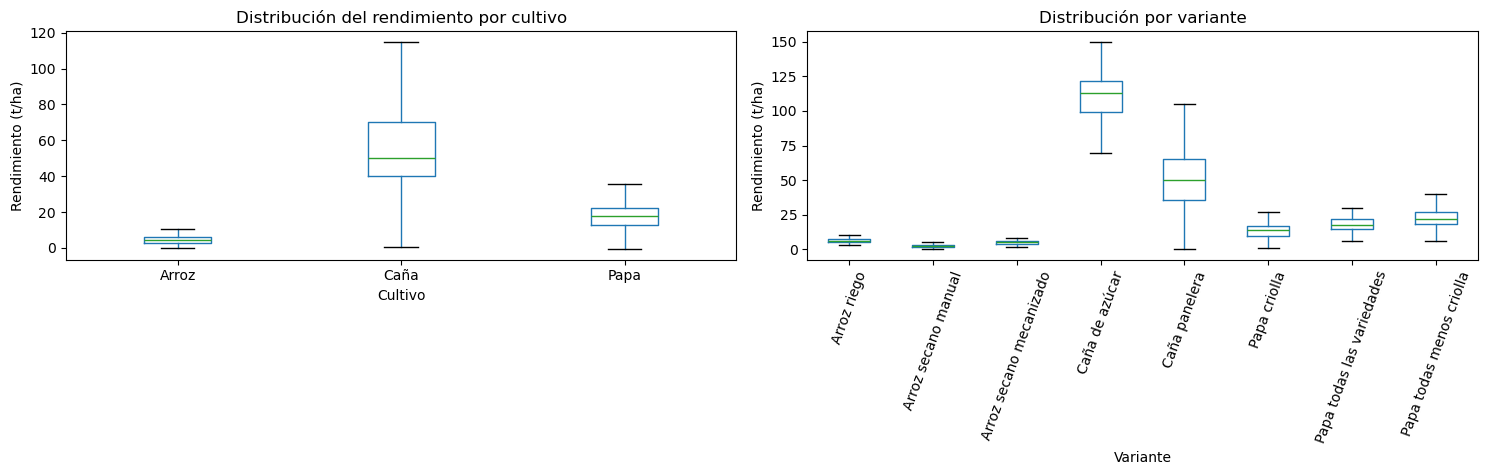

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
datos.boxplot(column="rendimiento", by="cultivo", ax=ejes[0], grid=False, showfliers=False)
ejes[0].set_title("Distribución del rendimiento por cultivo")
ejes[0].set_xlabel("Cultivo")
ejes[0].set_ylabel("Rendimiento (t/ha)")
ejes[0].get_figure().suptitle("")

datos.boxplot(column="rendimiento", by="variante", ax=ejes[1], grid=False, showfliers=False)
ejes[1].set_title("Distribución por variante")
ejes[1].set_xlabel("Variante")
ejes[1].set_ylabel("Rendimiento (t/ha)")
ejes[1].tick_params(axis="x", rotation=70)
ejes[1].get_figure().suptitle("")
plt.tight_layout()
plt.show()


## 6. Exploración orientada a la hipótesis: riego frente a secano

La comparación se realiza por variante y periodo. Aún no es una comparación climática, porque no se ha incorporado la clasificación Niño/neutro/Niña. Sin embargo, permite establecer una línea base agrícola y detectar si existen diferencias persistentes entre las modalidades de arroz.

Se muestran dos agregaciones: la mediana municipal y el rendimiento agregado. No se deben interpretar como la misma métrica.

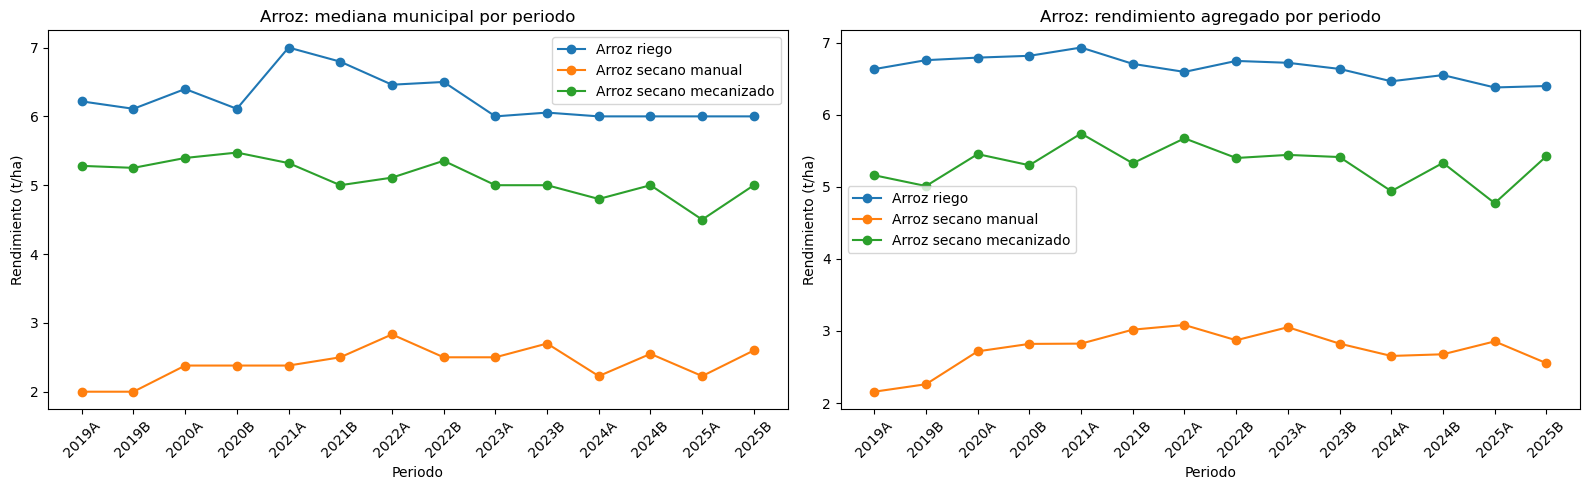

,periodo,variante,rendimiento_mediano,produccion_total,area_cosechada_total,municipios,rendimiento_agregado
0,2019A,Arroz riego,6.22,"830,834.49","125,193.76",122,6.64
1,2019A,Arroz secano manual,2.00,"96,033.83","44,521.45",143,2.16
2,2019A,Arroz secano mecanizado,5.28,"1,200,821.66","232,602.79",85,5.16
3,2019B,Arroz riego,6.11,"956,742.71","141,513.99",123,6.76
4,2019B,Arroz secano manual,2.00,"66,584.27","29,452.70",123,2.26
5,2019B,Arroz secano mecanizado,5.25,"299,951.46","59,836.59",81,5.01
6,2020A,Arroz riego,6.40,"904,963.72","133,157.36",118,6.80
7,2020A,Arroz secano manual,2.38,"126,509.23","46,553.45",149,2.72
8,2020A,Arroz secano mecanizado,5.40,"1,467,216.34","268,915.96",84,5.46
9,2020B,Arroz riego,6.11,"1,020,698.78","149,637.45",119,6.82


In [8]:
arroz = datos[datos["cultivo"] == "Arroz"].copy()
arroz_periodo = arroz.groupby(["periodo", "variante"], as_index=False).agg(
    rendimiento_mediano=("rendimiento", "median"),
    produccion_total=("producci_n", "sum"),
    area_cosechada_total=("rea_cosechada", "sum"),
    municipios=("c_digo_dane_municipio", "nunique"),
)
arroz_periodo["rendimiento_agregado"] = (
    arroz_periodo["produccion_total"] /
    arroz_periodo["area_cosechada_total"].replace(0, np.nan)
)

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
for variante, grupo in arroz_periodo.groupby("variante"):
    ejes[0].plot(grupo["periodo"], grupo["rendimiento_mediano"], marker="o", label=variante)
    ejes[1].plot(grupo["periodo"], grupo["rendimiento_agregado"], marker="o", label=variante)
ejes[0].set_title("Arroz: mediana municipal por periodo")
ejes[1].set_title("Arroz: rendimiento agregado por periodo")
for eje in ejes:
    eje.set_xlabel("Periodo")
    eje.set_ylabel("Rendimiento (t/ha)")
    eje.tick_params(axis="x", rotation=45)
    eje.legend()
plt.tight_layout()
plt.show()

display(arroz_periodo)


In [9]:
linea_base = arroz.groupby("variante", as_index=False).agg(
    rendimiento_mediano_base=("rendimiento", "median"),
    municipios=("c_digo_dane_municipio", "nunique"),
)
riego = linea_base.loc[
    linea_base["variante"] == "Arroz riego", "rendimiento_mediano_base"
].iloc[0]
secano = linea_base.loc[
    linea_base["variante"].str.contains("secano"), "rendimiento_mediano_base"
].mean()
brecha = (riego - secano) / riego * 100

print(f"Mediana base de arroz riego: {riego:.2f} t/ha")
print(f"Mediana promedio de arroz secano: {secano:.2f} t/ha")
print(f"Brecha descriptiva frente a riego: {brecha:.1f}%")
display(linea_base)

print(
    "Esta brecha es descriptiva y no demuestra un efecto de El Niño. "
    "Para probar la hipótesis se requiere una variable climática comparable por periodo y municipio."
)

Mediana base de arroz riego: 6.26 t/ha
Mediana promedio de arroz secano: 3.76 t/ha
Brecha descriptiva frente a riego: 40.0%


,variante,rendimiento_mediano_base,municipios
0,Arroz riego,6.26,137
1,Arroz secano manual,2.38,185
2,Arroz secano mecanizado,5.13,109


Esta brecha es descriptiva y no demuestra un efecto de El Niño. Para probar la hipótesis se requiere una variable climática comparable por periodo y municipio.


## 7. Limitaciones y decisiones pendientes

- **Clima:** EVA no contiene la etiqueta Niño/neutro/Niña, precipitación ni temperatura.
- **Causalidad:** con la información actual solo se observan asociaciones y diferencias temporales.
- **Cobertura:** las variantes no tienen el mismo número de municipios ni periodos reportados.
- **Ceros y faltantes:** un área cosechada igual a cero no debe interpretarse automáticamente como ausencia del cultivo.
- **Papa:** las categorías total y criolla no son aditivas; se debe conservar la regla de derivación.
- **Escala:** caña tiene rendimientos en una escala distinta a arroz y papa; conviene visualizar cultivos por separado.
- **Modelo:** aún no se han definido variables predictoras, horizonte de predicción, métrica de evaluación ni estrategia de validación temporal.

Estas limitaciones deben aparecer en el reporte para evitar afirmar que el dataset actual ya permite predecir el efecto climático.

## 8. Próximos pasos del grupo

### Paso 1 — Cerrar la especificación analítica
- Definir si el objetivo será rendimiento del siguiente periodo o rendimiento del periodo actual.
- Definir la granularidad final: municipio-cultivo-variante-periodo.
- Fijar una métrica primaria y una línea base para evaluar el modelo.

### Paso 2 — Incorporar información climática
- Seleccionar una fuente oficial o técnicamente documentada.
- Definir cómo se asigna el escenario climático a cada municipio y periodo.
- Documentar desfases: el clima puede afectar una cosecha cuyo reporte aparece después.

### Paso 3 — Completar la EDA
- Analizar faltantes, ceros, duplicados y valores extremos.
- Comparar riego y secano por periodo, municipio y escenario climático.
- Añadir mapas o rankings municipales solo si responden a la pregunta de negocio.

### Paso 4 — Construir el modelo
- Separar entrenamiento y prueba respetando el orden temporal.
- Comparar una línea base simple con modelos supervisados.
- Reportar MAE, RMSE y error por cultivo/variante, no solo un promedio global.

### Paso 5 — Producto y despliegue
- Empaquetar los modelos.
- Exponer inferencias mediante API.
- Conectar el tablero a la API y mostrar históricos como contexto.
- Containerizar con Docker y documentar cómo reproducir el sistema.

### Paso 6 — Evidencia de contribuciones
- Mantener commits propios, pequeños y descriptivos.
- Versionar el dato crudo con DVC y conservar el código de transformación en Git.
- Guardar en el reporte enlaces y capturas de Git y DVC.

## 9. Conclusión

La base procesada permite establecer una línea base descriptiva para arroz, papa y caña, conservar las variantes relevantes y evitar el doble conteo de papa. La comparación inicial muestra diferencias entre arroz de riego y de secano, pero todavía no identifica el efecto de El Niño.

La decisión crítica del grupo es integrar una fuente climática con una regla de asignación reproducible. A partir de esa integración se podrá evaluar la hipótesis, entrenar modelos supervisados y construir una API y un tablero coherentes con la pregunta de negocio.